<a href="https://colab.research.google.com/github/anmolubhi1/Handwritten-Digit-Recognition/blob/main/Mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Handwritten Digit Recognition

**1) Import Required Libraries**

This cell imports the necessary libraries for data manipulation, mathematical operations, and advanced data visualization.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.datasets import mnist

# Set random seed for reproducibility across runs
np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


**2) Load, Reshape, and Preprocess the Dataset**

We load MNIST directly from Keras, normalize pixel intensities, flatten the $28 \times 28$ images into 784-dimensional vectors, and one-hot encode the target labels.

In [2]:
print("Loading MNIST dataset from built-in Keras repository...")
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = mnist.load_data()

print(f"Original Training Shape: {X_train_raw.shape}")
print(f"Original Test Shape: {X_test_raw.shape}")

# 1. Reshape 2D images (28x28) into 1D vectors (784) and normalize pixels to range [0.0, 1.0]
X_train = X_train_raw.reshape(X_train_raw.shape[0], -1) / 255.0
X_test = X_test_raw.reshape(X_test_raw.shape[0], -1) / 255.0

# 2. One-hot encode labels (e.g., digit '3' becomes [0, 0, 0, 1, 0, 0, 0, 0, 0, 0])
def one_hot_encode(y, num_classes=10):
    return np.eye(num_classes)[y]

Y_train = one_hot_encode(y_train_raw)
Y_test = one_hot_encode(y_test_raw)

print(f"Processed Training Data Shape: {X_train.shape}")
print(f"Processed Training Labels Shape: {Y_train.shape}")

Loading MNIST dataset from built-in Keras repository...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Original Training Shape: (60000, 28, 28)
Original Test Shape: (10000, 28, 28)
Processed Training Data Shape: (60000, 784)
Processed Training Labels Shape: (60000, 10)


**3) Exploratory Data Analysis & Dataset Insights**

Let's analyze the dataset distribution using Seaborn and inspect a grid of actual handwritten digit samples.

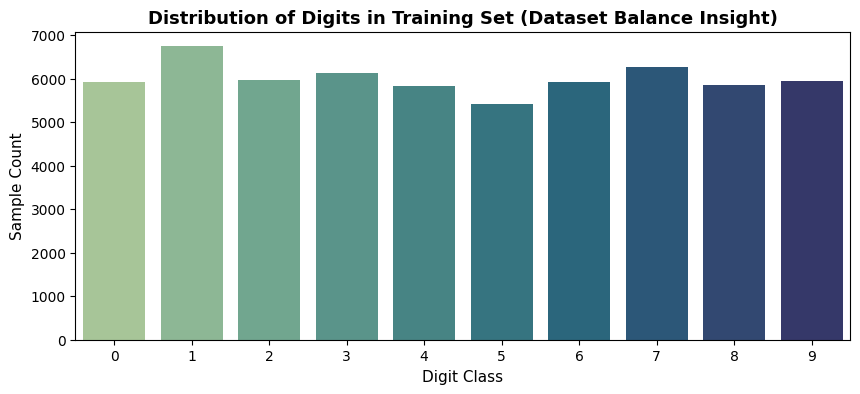

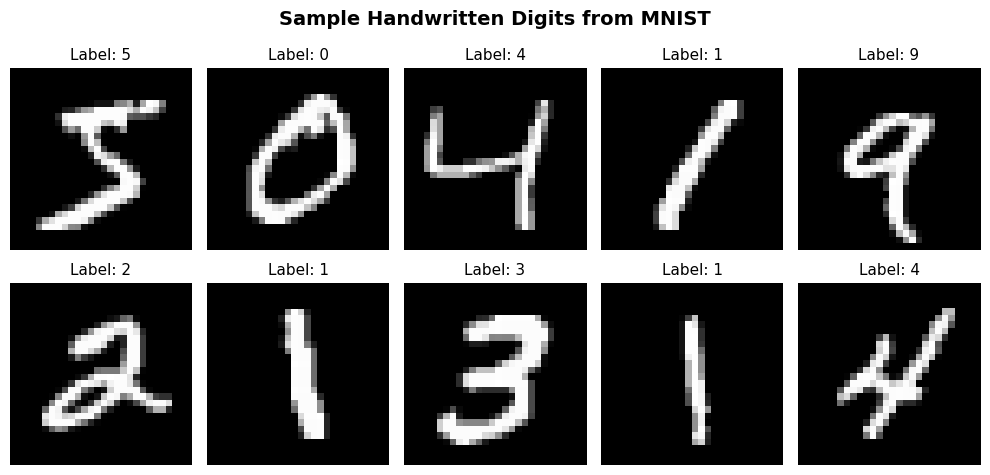

In [3]:
# Dataset Insight 1: Class Balance Check
plt.figure(figsize=(10, 4))
sns.countplot(x=y_train_raw, palette="crest", hue=y_train_raw, legend=False)
plt.title("Distribution of Digits in Training Set (Dataset Balance Insight)", fontsize=13, fontweight='bold')
plt.xlabel("Digit Class", fontsize=11)
plt.ylabel("Sample Count", fontsize=11)
plt.show()

# Dataset Insight 2: Visual Sample Preview
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(X_train_raw[i], cmap="gray")
    ax.set_title(f"Label: {y_train_raw[i]}", fontsize=11)
    ax.axis("off")
plt.suptitle("Sample Handwritten Digits from MNIST", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**4) Define Activation Functions, Derivatives, and Hyperparameters**

Backpropagation relies on the chain rule, which requires both activation functions and their mathematical derivatives.

In [4]:
# --- ACTIVATION FUNCTIONS & DERIVATIVES ---
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return np.where(x > 0, 1, 0)

def softmax(x):
    # Subtract max for numerical stability (prevents overflow)
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

# --- HYPERPARAMETERS ---
INPUT_SIZE = 784   # 28x28 pixels
HIDDEN_SIZE = 128  # Neurons in hidden layer
OUTPUT_SIZE = 10   # Digits 0 to 9
LEARNING_RATE = 0.05
EPOCHS = 15
BATCH_SIZE = 128

# --- WEIGHT INITIALIZATION (He Initialization) ---
W1 = np.random.randn(INPUT_SIZE, HIDDEN_SIZE) * np.sqrt(2.0 / INPUT_SIZE)
b1 = np.zeros((1, HIDDEN_SIZE))

W2 = np.random.randn(HIDDEN_SIZE, OUTPUT_SIZE) * np.sqrt(2.0 / HIDDEN_SIZE)
b2 = np.zeros((1, OUTPUT_SIZE))

print("Neural Network Architecture Initialized Successfully!")
print(f"W1 shape: {W1.shape}, b1 shape: {b1.shape}")
print(f"W2 shape: {W2.shape}, b2 shape: {b2.shape}")

Neural Network Architecture Initialized Successfully!
W1 shape: (784, 128), b1 shape: (1, 128)
W2 shape: (128, 10), b2 shape: (1, 10)


**5) The Training Loop & Manual Backpropagation Engine**

This is the core engine of the project. We train the network using mini-batch gradient descent, performing manual forward passes, categorical cross-entropy loss calculations, backward passes (chain rule), and parameter updates.

In [5]:
train_loss_history = []
train_acc_history = []

m_samples = X_train.shape[0]

print("Starting Backpropagation Training Loop...")
for epoch in range(EPOCHS):
    # Shuffle training data at the start of each epoch
    permutation = np.random.permutation(m_samples)
    X_shuffled = X_train[permutation]
    Y_shuffled = Y_train[permutation]

    epoch_loss = 0
    correct_preds = 0

    # Mini-batch gradient descent iteration
    for i in range(0, m_samples, BATCH_SIZE):
        X_batch = X_shuffled[i:i+BATCH_SIZE]
        Y_batch = Y_shuffled[i:i+BATCH_SIZE]
        current_batch_size = X_batch.shape[0]

        # ==========================================
        # 1. FORWARD PASS
        # ==========================================
        Z1 = np.dot(X_batch, W1) + b1
        A1 = relu(Z1)
        Z2 = np.dot(A1, W2) + b2
        A2 = softmax(Z2) # Output probabilities

        # ==========================================
        # 2. LOSS COMPUTATION (Cross-Entropy)
        # ==========================================
        clip_A2 = np.clip(A2, 1e-15, 1 - 1e-15)
        loss = -np.sum(Y_batch * np.log(clip_A2)) / current_batch_size
        epoch_loss += loss * current_batch_size

        # Track correct predictions for training accuracy
        preds = np.argmax(A2, axis=1)
        true_labels = np.argmax(Y_batch, axis=1)
        correct_preds += np.sum(preds == true_labels)

        # ==========================================
        # 3. BACKWARD PASS (THE CHAIN RULE ENGINE)
        # ==========================================
        # Output layer gradient (Softmax + Cross-Entropy derivative simplifies to A2 - Y)
        dZ2 = A2 - Y_batch
        dW2 = np.dot(A1.T, dZ2) / current_batch_size
        db2 = np.sum(dZ2, axis=0, keepdims=True) / current_batch_size

        # Hidden layer error propagation (Chain Rule)
        dZ1 = np.dot(dZ2, W2.T) * relu_derivative(Z1)
        dW1 = np.dot(X_batch.T, dZ1) / current_batch_size
        db1 = np.sum(dZ1, axis=0, keepdims=True) / current_batch_size

        # ==========================================
        # 4. WEIGHT UPDATE (Gradient Descent Step)
        # ==========================================
        W1 -= LEARNING_RATE * dW1
        b1 -= LEARNING_RATE * db1
        W2 -= LEARNING_RATE * dW2
        b2 -= LEARNING_RATE * db2

    # Record metrics for this epoch
    epoch_loss /= m_samples
    epoch_acc = correct_preds / m_samples
    train_loss_history.append(epoch_loss)
    train_acc_history.append(epoch_acc)

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | Loss: {epoch_loss:.4f} | Training Accuracy: {epoch_acc*100:.2f}%")

print("\nTraining Completed Successfully!")

Starting Backpropagation Training Loop...
Epoch 01/15 | Loss: 0.5994 | Training Accuracy: 84.37%
Epoch 02/15 | Loss: 0.3180 | Training Accuracy: 90.96%
Epoch 03/15 | Loss: 0.2711 | Training Accuracy: 92.36%
Epoch 04/15 | Loss: 0.2407 | Training Accuracy: 93.23%
Epoch 05/15 | Loss: 0.2172 | Training Accuracy: 93.90%
Epoch 06/15 | Loss: 0.1977 | Training Accuracy: 94.49%
Epoch 07/15 | Loss: 0.1816 | Training Accuracy: 94.90%
Epoch 08/15 | Loss: 0.1679 | Training Accuracy: 95.27%
Epoch 09/15 | Loss: 0.1561 | Training Accuracy: 95.67%
Epoch 10/15 | Loss: 0.1462 | Training Accuracy: 95.94%
Epoch 11/15 | Loss: 0.1371 | Training Accuracy: 96.17%
Epoch 12/15 | Loss: 0.1293 | Training Accuracy: 96.41%
Epoch 13/15 | Loss: 0.1225 | Training Accuracy: 96.59%
Epoch 14/15 | Loss: 0.1158 | Training Accuracy: 96.78%
Epoch 15/15 | Loss: 0.1103 | Training Accuracy: 96.96%

Training Completed Successfully!


**6) Visualizing Training Loss & Accuracy Curves**

We use Seaborn and Matplotlib to plot how backpropagation successfully minimized loss and maximized accuracy across epochs.

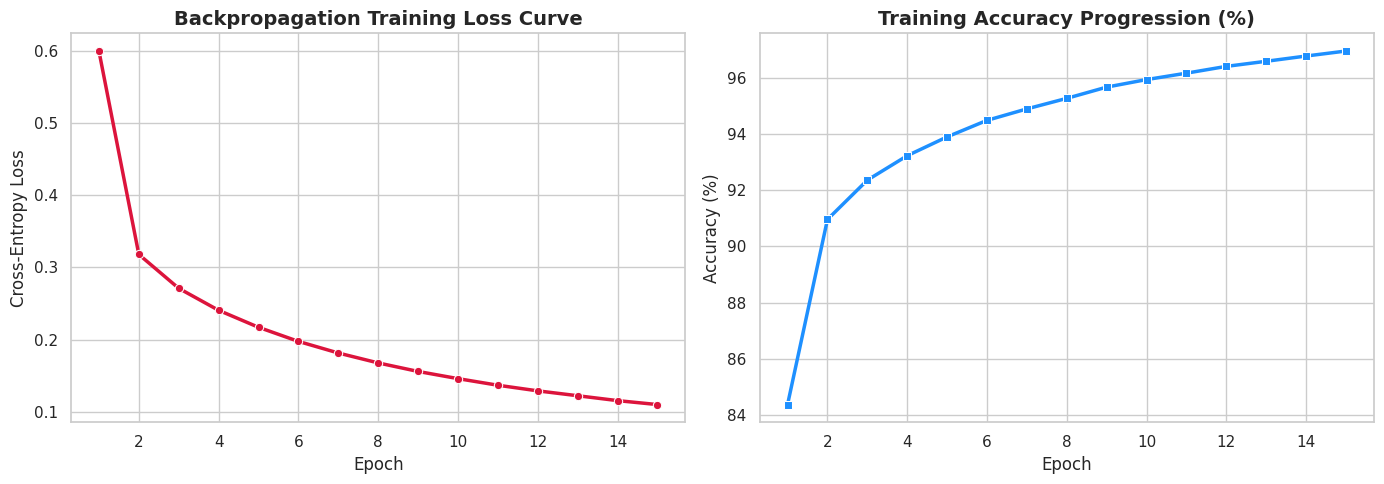

In [6]:
sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Loss Curve
sns.lineplot(x=range(1, EPOCHS + 1), y=train_loss_history, ax=axes[0], color='crimson', linewidth=2.5, marker='o')
axes[0].set_title('Backpropagation Training Loss Curve', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Cross-Entropy Loss', fontsize=12)

# Plot 2: Accuracy Curve
sns.lineplot(x=range(1, EPOCHS + 1), y=[acc * 100 for acc in train_acc_history], ax=axes[1], color='dodgerblue', linewidth=2.5, marker='s')
axes[1].set_title('Training Accuracy Progression (%)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Accuracy (%)', fontsize=12)

plt.tight_layout()
plt.show()

**7) Model Evaluation, Testing, and Confusion Matrix**

We test our trained network on unseen test data and generate a Seaborn confusion matrix heatmap to evaluate classification performance across all digit classes.

=== FINAL TEST EVALUATION ===
Unseen Test Accuracy: 96.59%

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.98      0.99      0.98      1135
           2       0.96      0.97      0.96      1032
           3       0.97      0.96      0.97      1010
           4       0.96      0.97      0.96       982
           5       0.97      0.95      0.96       892
           6       0.96      0.97      0.97       958
           7       0.97      0.96      0.96      1028
           8       0.96      0.96      0.96       974
           9       0.97      0.94      0.95      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



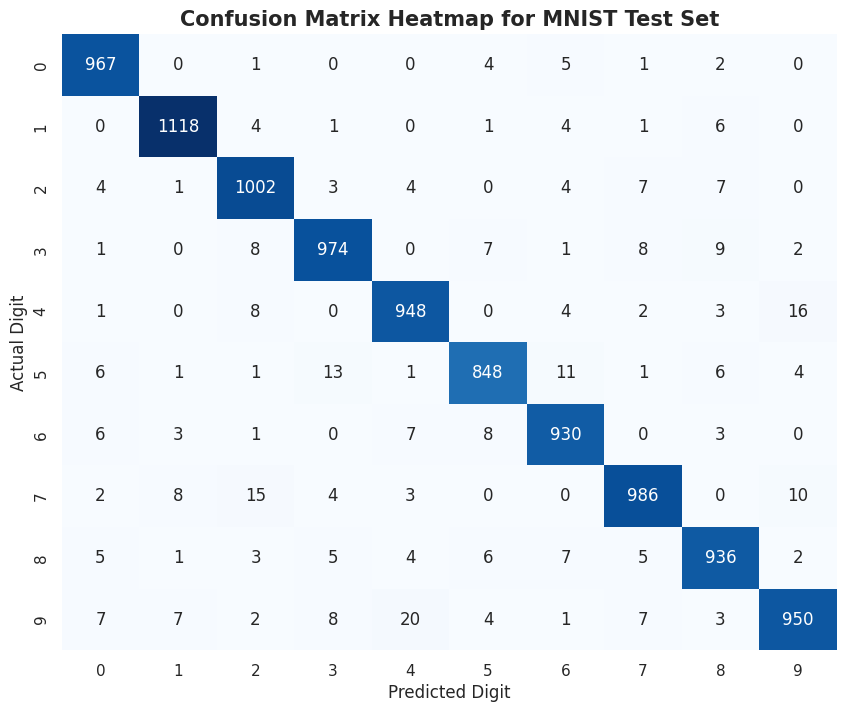

In [7]:
from sklearn.metrics import confusion_matrix, classification_report

# --- FORWARD PASS ON UNSEEN TEST DATA ---
Z1_test = np.dot(X_test, W1) + b1
A1_test = relu(Z1_test)
Z2_test = np.dot(A1_test, W2) + b2
A2_test = softmax(Z2_test)

test_preds = np.argmax(A2_test, axis=1)
test_accuracy = np.mean(test_preds == y_test_raw)

print(f"=== FINAL TEST EVALUATION ===")
print(f"Unseen Test Accuracy: {test_accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test_raw, test_preds))

# --- PLOT CONFUSION MATRIX HEATMAP ---
cm = confusion_matrix(y_test_raw, test_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=range(10), yticklabels=range(10))
plt.title('Confusion Matrix Heatmap for MNIST Test Set', fontsize=15, fontweight='bold')
plt.xlabel('Predicted Digit', fontsize=12)
plt.ylabel('Actual Digit', fontsize=12)
plt.show()